# 02. Baseline Model Training Plant Disease Classification

## 1. Introduction

This notebook focuses on developing and evaluating a baseline deep learning model for the PlantVillage plant disease classification project.

In the previous notebook (`01_data_understanding.ipynb`), we explored, cleaned, and validated the dataset. We prepared three leakage-free datasets:

- **Training set:** 34,880 images
- **Validation set:** 8,702 images
- **Testing set:** 10,464 images

The prepared dataset contains **38 plant disease and healthy-condition classes across 14 crops**. All images have been standardized to RGB format and resized to 256 × 256 pixels.

### 1.1 Objectives

The main objectives of this notebook are to:

1. Load and inspect the prepared training, validation, and testing datasets.
2. Apply the preprocessing required by our selected pretrained architecture.
3. Develop a baseline image classification model using transfer learning.
4. Train the model and monitor training and validation performance.
5. Apply optimization techniques such as suitable optimizers, regularization, and early stopping.
6. Evaluate model performance using accuracy, precision, recall, F1-score, loss, and a confusion matrix.
7. Save the trained model and class mapping for future prediction and deployment.

### 1.2 Modeling Approach

We will begin with a pretrained convolutional neural network and adapt its classification head to recognize the 38 target classes.

Transfer learning allows us to leverage features learned from a large image dataset rather than training an entire deep learning architecture from scratch.

We will initially freeze the pretrained feature extraction layers and train the classification head. Depending on the baseline results, we may fine-tune selected layers to improve performance.

### 1.3 Expected Outputs

By the end of this notebook, we aim to produce:

- A trained baseline classification model.
- Training and validation performance visualizations.
- A comprehensive evaluation report.
- A confusion matrix and per-class performance metrics.
- A saved model ready for prediction and further development.



In [2]:
# Install the dataset library
!pip install -q datasets

In [1]:
# General libraries
import os
import json
import zipfile
import random
from pathlib import Path

# Data handling
import numpy as np
import pandas as pd

# Image handling and visualization
import matplotlib.pyplot as plt
from PIL import Image

# Hugging Face datasets
from datasets import load_from_disk

import tensorflow as tf

# Reproducibility
random.seed(42)
np.random.seed(42)

print("Libraries imported successfully.")

Libraries imported successfully.


In [4]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
zip_path = "/content/drive/MyDrive/PlantDiseaseClassification/plantvillage_prepared.zip"

extract_dir = "/content"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_dir)

print("Dataset extracted successfully!")

Dataset extracted successfully!


we are training an image classification model using transfer learning, we will check the TensorFlow version and GPU availability. We will also confirm that the prepared training, validation, and testing datasets are accessible.

This ensures that our training environment is configured correctly before starting model development.

In [6]:
print("TensorFlow version:", tf.__version__)

gpus = tf.config.list_physical_devices("GPU")

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", gpus)

if gpus:
    print("GPU is ready for training!")
else:
    print("GPU is still unavailable. Check runtime settings.")

TensorFlow version: 2.21.0
TensorFlow version: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
GPU is ready for training!


In [2]:
dataset_path = Path("/content/plantvillage_prepared")
# Load datasets
prepared_datasets = load_from_disk(str(dataset_path))

train_data = prepared_datasets["train"]
val_data = prepared_datasets["validation"]
test_data = prepared_datasets["test"]

# Retrieve class names
class_names = train_data.features["label"].names

print("Datasets loaded successfully!")

Datasets loaded successfully!


In [3]:
# Dataset sizes
print("\nDATASET SIZES")
print("Training:", len(train_data))
print("Validation:", len(val_data))
print("Testing:", len(test_data))

# Class information
print("\nCLASS INFORMATION")
print("Number of classes:", len(class_names))
print("First five classes:", class_names[:5])

# Verify expected values
assert len(train_data) == 34880
assert len(val_data) == 8702
assert len(test_data) == 10464
assert len(class_names) == 38

print("\nAll dataset checks passed!")


DATASET SIZES
Training: 34880
Validation: 8702
Testing: 10464

CLASS INFORMATION
Number of classes: 38
First five classes: ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy']

All dataset checks passed!


### 2.2 Image Preprocessing

In this section, we will prepare the PlantVillage images for our MobileNetV2 transfer-learning model.

The original images are RGB and have dimensions of 256 × 256 pixels. However, MobileNetV2 will receive images resized to 224 × 224 pixels.

We will also apply the preprocessing function recommended for MobileNetV2, which scales pixel values from the original range of [0, 255] to [-1, 1].

Data augmentation will be applied exclusively to the training dataset to improve the model's ability to generalize to unseen images. Validation and testing images will only undergo resizing and normalization.

In [4]:
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# Image configuration
IMG_SIZE = 224
BATCH_SIZE = 32
NUM_CLASSES = len(class_names)

print("Image preprocessing configuration:")
print("Target image size:", IMG_SIZE, "x", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Number of classes:", NUM_CLASSES)

Image preprocessing configuration:
Target image size: 224 x 224
Batch size: 32
Number of classes: 38


Original image shape: (256, 256, 3)
Original image data type: uint8
Original pixel range: 0 to 255
Image class: Raspberry___healthy


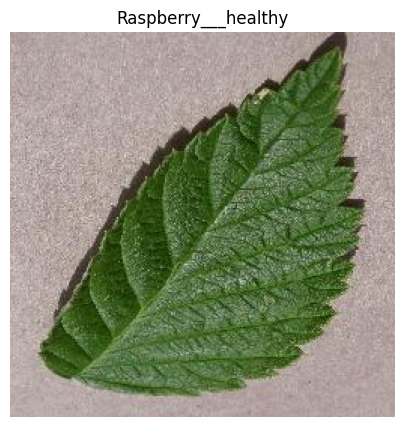

In [5]:
# Select one training image
sample = train_data[0]

original_image = np.array(
    sample["image"].convert("RGB")
)

original_label = sample["label"]

print("Original image shape:", original_image.shape)
print("Original image data type:", original_image.dtype)
print("Original pixel range:",
      original_image.min(), "to", original_image.max())
print("Image class:", class_names[original_label])

# Display original image
plt.figure(figsize=(5, 5))
plt.imshow(original_image)
plt.title(class_names[original_label])
plt.axis("off")
plt.show()

In [6]:
def preprocess_image(image):
    """
    Resize an image to 224x224 and apply
    MobileNetV2 preprocessing.
    """

    # Ensure RGB format
    image = image.convert("RGB")

    # Convert image to NumPy array
    image = np.array(image, dtype=np.float32)

    # Convert to TensorFlow tensor
    image = tf.convert_to_tensor(image)

    # Resize image
    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE]
    )

    # Apply MobileNetV2 preprocessing
    image = preprocess_input(image)

    return image

In [7]:
# Preprocess one sample image
processed_image = preprocess_image(sample["image"])

print("Processed image shape:", processed_image.shape)
print("Processed image data type:", processed_image.dtype)
print(
    "Processed pixel range:",
    float(tf.reduce_min(processed_image)),
    "to",
    float(tf.reduce_max(processed_image))
)

Processed image shape: (224, 224, 3)
Processed image data type: <dtype: 'float32'>
Processed pixel range: -1.0 to 0.7992373704910278


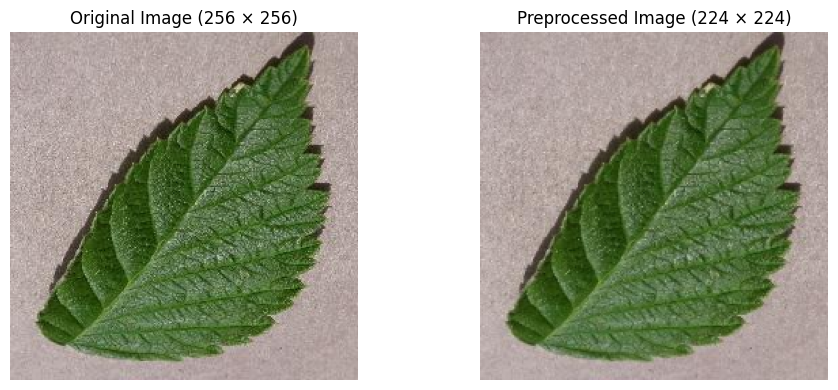

In [8]:
# Convert normalized image back to display range
display_image = (processed_image.numpy() + 1.0) / 2.0

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(original_image)
plt.title("Original Image (256 × 256)")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(np.clip(display_image, 0, 1))
plt.title("Preprocessed Image (224 × 224)")
plt.axis("off")

plt.tight_layout()
plt.show()

In [9]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),

    tf.keras.layers.RandomRotation(
        factor=0.08,
        fill_mode="reflect"
    ),

    tf.keras.layers.RandomZoom(
        height_factor=0.10,
        width_factor=0.10,
        fill_mode="reflect"
    )
], name="data_augmentation")

print("Data augmentation pipeline created!")

Data augmentation pipeline created!


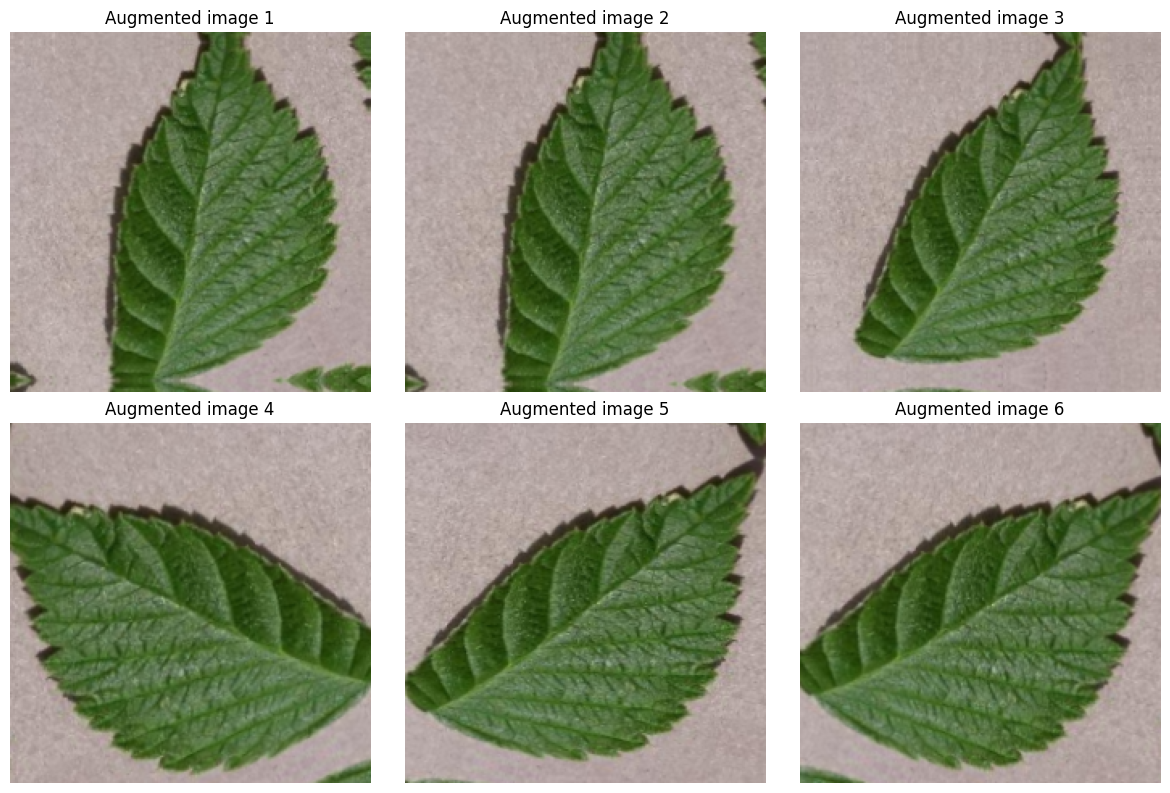

In [10]:
# Resize the sample without normalization
resized_sample = tf.image.resize(
    original_image.astype(np.float32),
    [IMG_SIZE, IMG_SIZE]
)

plt.figure(figsize=(12, 8))

for i in range(6):
    augmented_image = data_augmentation(
        tf.expand_dims(resized_sample, axis=0),
        training=True
    )

    # Convert back to display range
    augmented_image = tf.clip_by_value(
        augmented_image[0] / 255.0,
        0,
        1
    )

    plt.subplot(2, 3, i + 1)
    plt.imshow(augmented_image.numpy())
    plt.title(f"Augmented image {i + 1}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [11]:
print("Preprocessing Verfication")

print("Original shape:", original_image.shape)
print("Processed shape:", processed_image.shape)

print(
    "Normalized pixel range:",
    float(tf.reduce_min(processed_image)),
    "to",
    float(tf.reduce_max(processed_image))
)

assert processed_image.shape == (224, 224, 3)
assert float(tf.reduce_min(processed_image)) >= -1.0
assert float(tf.reduce_max(processed_image)) <= 1.0

print("\nPreprocessing verification passed!")

Preprocessing Verfication
Original shape: (256, 256, 3)
Processed shape: (224, 224, 3)
Normalized pixel range: -1.0 to 0.7992373704910278

Preprocessing verification passed!


### 2.3 Building TensorFlow Data Pipelines

The prepared datasets are stored as Hugging Face datasets. We will convert them into TensorFlow-compatible datasets using `tf.data.Dataset.from_generator`.

This approach allows us to load images progressively rather than converting all images into large in-memory arrays.

We will create separate pipelines for training, validation, and testing, ensuring that augmentation and shuffling are applied only where appropriate.

In [12]:
def hf_dataset_generator(hf_dataset):
    """
    Generate RGB image arrays and integer labels
    from a Hugging Face dataset.
    """

    for example in hf_dataset:
        image = example["image"].convert("RGB")

        image = np.asarray(image, dtype=np.uint8)
        label = np.int64(example["label"])

        yield image, label


# Define the expected image and label structures
output_signature = (
    tf.TensorSpec(
        shape=(256, 256, 3),
        dtype=tf.uint8
    ),
    tf.TensorSpec(
        shape=(),
        dtype=tf.int64
    )
)

print("Data generator and output signature defined successfully!")

Data generator and output signature defined successfully!


In [13]:
train_raw = tf.data.Dataset.from_generator(
    lambda: hf_dataset_generator(train_data),
    output_signature=output_signature
)

val_raw = tf.data.Dataset.from_generator(
    lambda: hf_dataset_generator(val_data),
    output_signature=output_signature
)

test_raw = tf.data.Dataset.from_generator(
    lambda: hf_dataset_generator(test_data),
    output_signature=output_signature
)

print("TensorFlow datasets created successfully!")

TensorFlow datasets created successfully!


In [16]:
data_augmentation = tf.keras.Sequential([
    tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),

    tf.keras.layers.RandomFlip("horizontal"),

    tf.keras.layers.RandomRotation(
        factor=0.08,
        fill_mode="reflect"
    ),

    tf.keras.layers.RandomZoom(
        height_factor=0.10,
        width_factor=0.10,
        fill_mode="reflect"
    )

], name="data_augmentation")

print("Augmentation pipeline recreated successfully!")

Augmentation pipeline recreated successfully!


In [21]:
def preprocess_training(image, label):

    # Resize image
    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE]
    )

    # Add temporary batch dimension
    image = tf.expand_dims(image, axis=0)

    # Apply augmentation
    image = data_augmentation(
        image,
        training=True
    )

    # Remove temporary batch dimension
    image = tf.squeeze(image, axis=0)

    # Apply MobileNetV2 normalization
    image = preprocess_input(image)

    return image, label


def preprocess_evaluation(image, label):
    # Resize image
    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE]
    )

    # No augmentation for validation or testing
    image = preprocess_input(image)

    return image, label


print("Training and evaluation preprocessing functions defined!")

Training and evaluation preprocessing functions defined!


In [22]:
AUTOTUNE = tf.data.AUTOTUNE

# Training pipeline
train_dataset = (
    train_raw
    .shuffle(
        buffer_size=1000,
        seed=42,
        reshuffle_each_iteration=True
    )
    .map(
        preprocess_training,
        num_parallel_calls=AUTOTUNE
    )
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

# Validation pipeline
val_dataset = (
    val_raw
    .map(
        preprocess_evaluation,
        num_parallel_calls=AUTOTUNE
    )
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

# Testing pipeline
test_dataset = (
    test_raw
    .map(
        preprocess_evaluation,
        num_parallel_calls=AUTOTUNE
    )
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

print("All three TensorFlow data pipelines created successfully!")

All three TensorFlow data pipelines created successfully!


In [23]:
def inspect_pipeline(dataset, name):
    images, labels = next(iter(dataset))

    print(f"\n{name} PIPELINE")
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Image data type:", images.dtype)
    print("Label data type:", labels.dtype)
    print(
        "Pixel range:",
        float(tf.reduce_min(images)),
        "to",
        float(tf.reduce_max(images))
    )
    print("First five labels:", labels[:5].numpy())

    # Verify image dimensions and normalization
    assert images.shape[1:] == (224, 224, 3)
    assert labels.dtype == tf.int64
    assert float(tf.reduce_min(images)) >= -1.0
    assert float(tf.reduce_max(images)) <= 1.0


inspect_pipeline(train_dataset, "TRAINING")
inspect_pipeline(val_dataset, "VALIDATION")
inspect_pipeline(test_dataset, "TESTING")

print("\nAll pipeline checks passed!")


TRAINING PIPELINE
Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Image data type: <dtype: 'float32'>
Label data type: <dtype: 'int64'>
Pixel range: -0.9999874830245972 to 1.0
First five labels: [23  7 23 23 21]

VALIDATION PIPELINE
Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Image data type: <dtype: 'float32'>
Label data type: <dtype: 'int64'>
Pixel range: -1.0 to 0.9625824689865112
First five labels: [23 23 23 23 23]

TESTING PIPELINE
Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Image data type: <dtype: 'float32'>
Label data type: <dtype: 'int64'>
Pixel range: -1.0 to 1.0
First five labels: [23 23 23 23 23]

All pipeline checks passed!


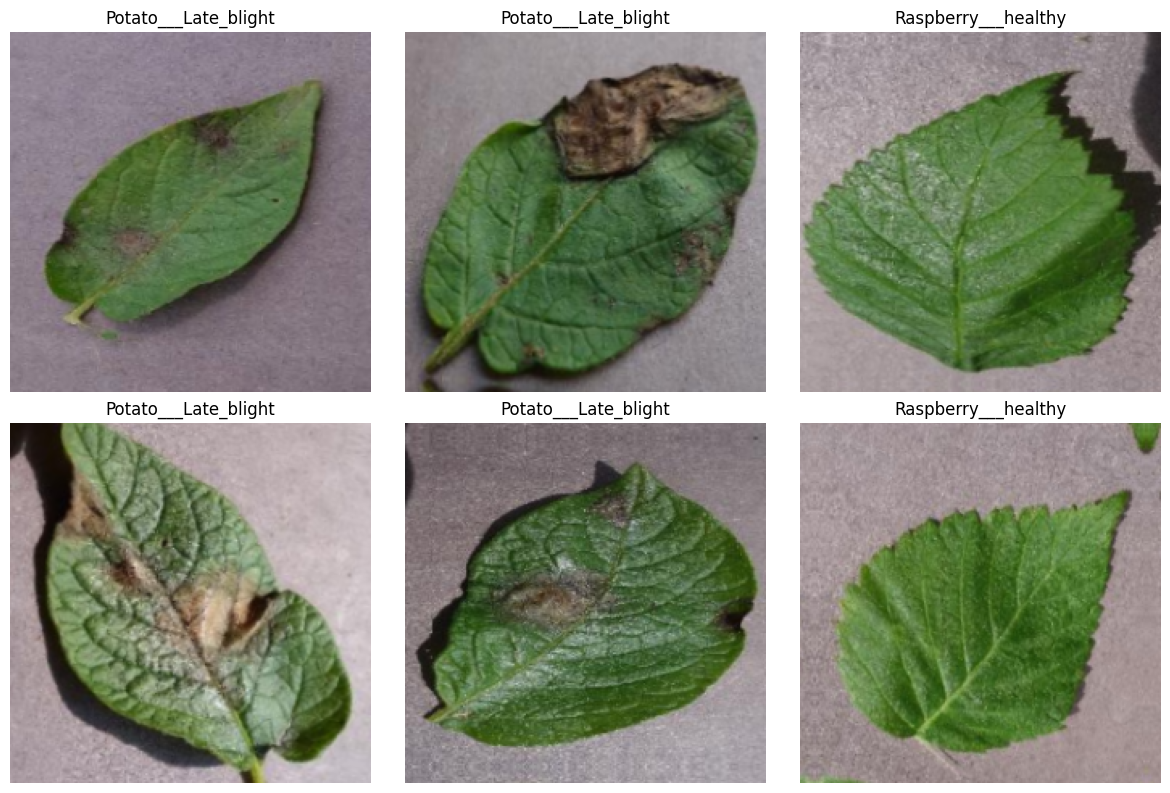

In [24]:
images, labels = next(iter(train_dataset))

plt.figure(figsize=(12, 8))

for i in range(6):
    display_image = (images[i].numpy() + 1.0) / 2.0

    plt.subplot(2, 3, i + 1)
    plt.imshow(np.clip(display_image, 0, 1))
    plt.title(class_names[int(labels[i])])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [25]:
# Use the same original image twice
test_image = tf.cast(
    tf.convert_to_tensor(original_image),
    tf.uint8
)

test_label = tf.constant(0, dtype=tf.int64)

# Apply training preprocessing twice
train_image_1, _ = preprocess_training(
    test_image, test_label
)

train_image_2, _ = preprocess_training(
    test_image, test_label
)

# Apply evaluation preprocessing twice
eval_image_1, _ = preprocess_evaluation(
    test_image, test_label
)

eval_image_2, _ = preprocess_evaluation(
    test_image, test_label
)

# Calculate differences
training_difference = tf.reduce_mean(
    tf.abs(train_image_1 - train_image_2)
)

evaluation_difference = tf.reduce_max(
    tf.abs(eval_image_1 - eval_image_2)
)

print("Training image difference:", float(training_difference))
print("Evaluation image difference:", float(evaluation_difference))

Training image difference: 0.23706652224063873
Evaluation image difference: 0.0
